# Lab 1

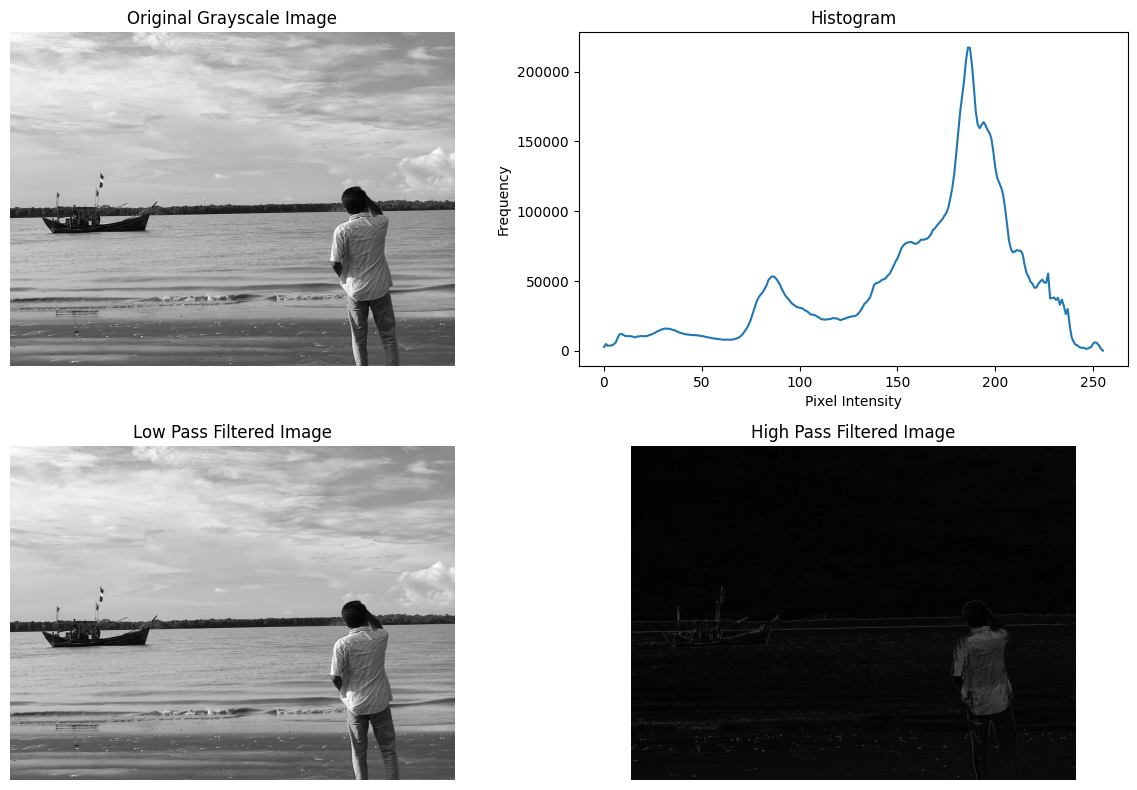

In [2]:
# Display following image operation in MATLAB/Python - i) Histogram  
# image  ii) Low pass filter mage  iii) High pass image. 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------
# Read Image
# --------------------------------

img = cv2.imread( r"C:\Users\Jayed\OneDrive\Pictures\Desktop\3.2\image and speech\maksudul.jpg")

# Check if image loaded properly
if img is None:
    print("Error: Image not found. Check the file path/name.")
    exit()

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# --------------------------------
# i) Histogram
# --------------------------------

hist = cv2.calcHist([gray], [0], None, [256], [0, 256])

# --------------------------------
# ii) Low Pass Filter
# --------------------------------

low_pass = cv2.GaussianBlur(gray, (5, 5), 0)

# --------------------------------
# iii) High Pass Filter
# --------------------------------

kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

high_pass = cv2.filter2D(gray, -1, kernel)

# --------------------------------
# Display Results
# --------------------------------

plt.figure(figsize=(12, 8))

# Original Image
plt.subplot(2, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

# Histogram
plt.subplot(2, 2, 2)
plt.plot(hist)
plt.title('Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')

# Low Pass Filter
plt.subplot(2, 2, 3)
plt.imshow(low_pass, cmap='gray')
plt.title('Low Pass Filtered Image')
plt.axis('off')

# High Pass Filter
plt.subplot(2, 2, 4)
plt.imshow(high_pass, cmap='gray')
plt.title('High Pass Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()

# Lab 2

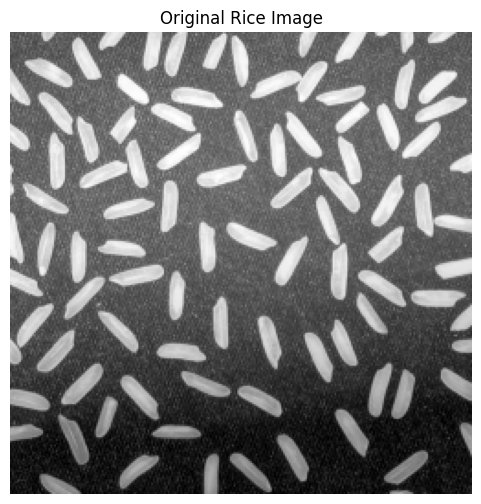

Number of rice grains: 83

Rice No.	Area		Major Axis Length	Perimeter
-----------------------------------------------------------------
1		85.00		14.37			34.73
2		163.00		23.27			53.31
3		195.00		26.91			61.21
4		89.00		14.95			36.73
5		154.00		21.79			52.04
6		65.00		11.61			29.66
7		66.00		14.38			31.28
8		144.00		22.10			51.21
9		188.00		29.03			62.97
10		197.00		26.97			61.11
11		213.00		28.52			64.28
12		425.00		45.79			122.81
13		195.00		28.25			62.38
14		193.00		26.74			58.18
15		113.00		19.55			45.80
16		162.00		23.27			52.53
17		188.00		28.00			61.80
18		232.00		29.90			67.21
19		210.00		28.92			63.60
20		208.00		30.50			67.70
21		152.00		23.25			50.77
22		205.00		27.51			63.46
23		188.00		27.25			60.28
24		159.00		21.37			51.70
25		199.00		31.08			66.87
26		224.00		30.85			67.01
27		186.00		26.39			60.63
28		193.00		28.26			61.01
29		211.00		30.61			65.56
30		104.00		15.68			38.97
31		222.00		30.95			67.31
32		206.00		30.52			65.60
33		442.00		40.38			131.05
34		419.00		43.81

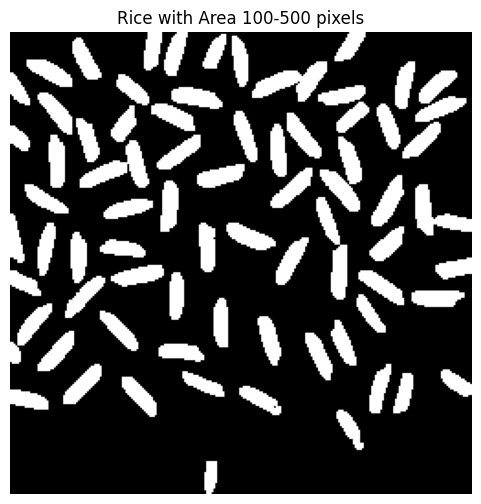

In [1]:
# Write a MATLAB/Python program to read ‘rice.tif’ image, count number of 
# rice and display area (also specific range), major axis length, and perimeter. 

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops

# Read rice image
image = cv2.imread("rice.tif", cv2.IMREAD_GRAYSCALE)

# Display original image
plt.figure(figsize=(6, 6))
plt.imshow(image, cmap="gray")
plt.title("Original Rice Image")
plt.axis("off")
plt.show()

# Convert image to binary
_, binary = cv2.threshold(
    image, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Remove small noise
kernel = np.ones((3, 3), np.uint8)
binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)

# Label connected rice grains
label_image = label(binary > 0)

# Measure properties
properties = regionprops(label_image)

# Remove very small objects
properties = [p for p in properties if p.area > 50]

# Number of rice grains
number_of_rice = len(properties)

print("Number of rice grains:", number_of_rice)
print()

# Display measurements
print("Rice No.\tArea\t\tMajor Axis Length\tPerimeter")
print("-" * 65)

for i, prop in enumerate(properties, start=1):
    print(
        f"{i}\t\t"
        f"{prop.area:.2f}\t\t"
        f"{prop.major_axis_length:.2f}\t\t\t"
        f"{prop.perimeter:.2f}"
    )

# ---------------------------------------
# Specific Area Range
# ---------------------------------------

min_area = 100
max_area = 500

selected_rice = [
    p for p in properties
    if min_area <= p.area <= max_area
]

print()
print(f"Rice with area between {min_area} and {max_area}: "
      f"{len(selected_rice)}")

# Display selected rice grains
selected_image = np.zeros_like(label_image)

for p in selected_rice:
    selected_image[label_image == p.label] = 1

plt.figure(figsize=(6, 6))
plt.imshow(selected_image, cmap="gray")
plt.title(
    f"Rice with Area {min_area}-{max_area} pixels"
)
plt.axis("off")
plt.show()

# Lab 3

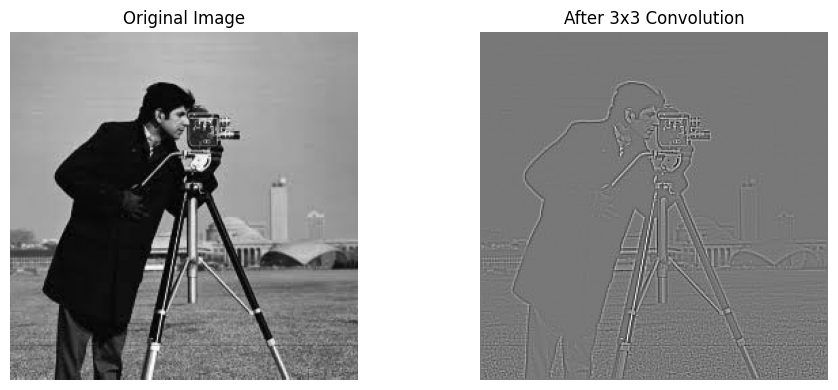

In [5]:
 
# Write a MATLAB/Python program to read an image and perform 
# convolution with 3X3 mask. 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
image = cv2.imread(r"C:\Users\Jayed\OneDrive\Pictures\Desktop\3.2\image and speech\cameraman.jpeg", cv2.IMREAD_GRAYSCALE)

# 3x3 mask
mask = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# Get image dimensions
rows, cols = image.shape

# Create output image
output = np.zeros((rows, cols), dtype=np.float32)

# Perform convolution manually
for i in range(1, rows - 1):
    for j in range(1, cols - 1):

        region = image[i-1:i+2, j-1:j+2]

        output[i, j] = np.sum(region * mask)

# Normalize result for display
output = cv2.normalize(
    output,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Display
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output, cmap="gray")
plt.title("After 3x3 Convolution")
plt.axis("off")

plt.tight_layout()
plt.show()

# Lab 4

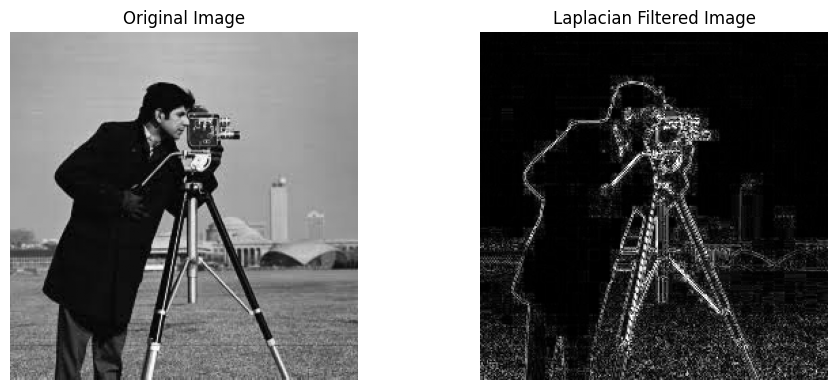

In [6]:
# Write a MATLAB/Python program to read an image and perform Lapliciant 
# filter mask. 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
image = cv2.imread(r"C:\Users\Jayed\OneDrive\Pictures\Desktop\3.2\image and speech\cameraman.jpeg", cv2.IMREAD_GRAYSCALE)

# Define 3x3 Laplacian filter mask
mask = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
])

# Apply Laplacian filter
laplacian = cv2.filter2D(image, cv2.CV_64F, mask)

# Convert result to displayable image
laplacian = np.absolute(laplacian)
laplacian = np.uint8(np.clip(laplacian, 0, 255))

# Display results
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian Filtered Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Lab 6

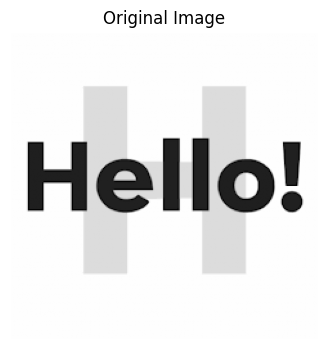

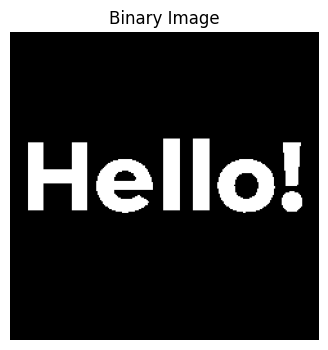

Number of segmented characters: 7


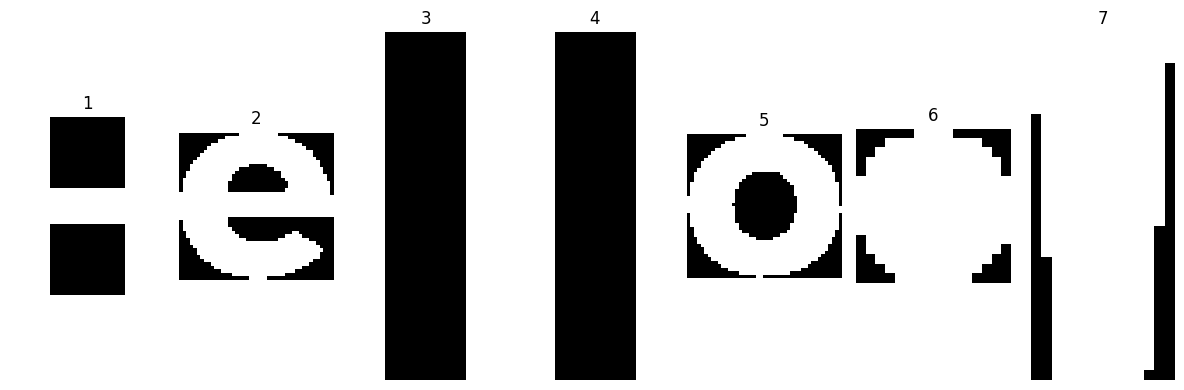

In [10]:
# Write a MATLAB/Python program to Character Segment of an image.  

import cv2
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------
# 1. Read the image
# -----------------------------------
image = cv2.imread( r"C:\Users\Jayed\OneDrive\Pictures\Desktop\3.2\image and speech\hello.png", cv2.IMREAD_GRAYSCALE)

# Display original image
plt.figure(figsize=(10, 4))
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

# -----------------------------------
# 2. Convert image to binary
# -----------------------------------
_, binary = cv2.threshold(
    image, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Display binary image
plt.figure(figsize=(10, 4))
plt.imshow(binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()

# -----------------------------------
# 3. Find connected components
# -----------------------------------
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    binary,
    connectivity=8
)

# List to store character images
characters = []

# -----------------------------------
# 4. Extract individual characters
# -----------------------------------
for i in range(1, num_labels):

    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]
    area = stats[i, cv2.CC_STAT_AREA]

    # Remove very small noise
    if area > 20:

        character = binary[y:y+h, x:x+w]

        characters.append((x, y, w, h, character))

# Sort characters from left to right
characters.sort(key=lambda c: c[0])

# -----------------------------------
# 5. Display segmented characters
# -----------------------------------

print("Number of segmented characters:", len(characters))

plt.figure(figsize=(12, 4))

for i, (x, y, w, h, character) in enumerate(characters):

    plt.subplot(1, len(characters), i + 1)
    plt.imshow(character, cmap="gray")
    plt.title(str(i + 1))
    plt.axis("off")

plt.tight_layout()
plt.show()

# Lab 7

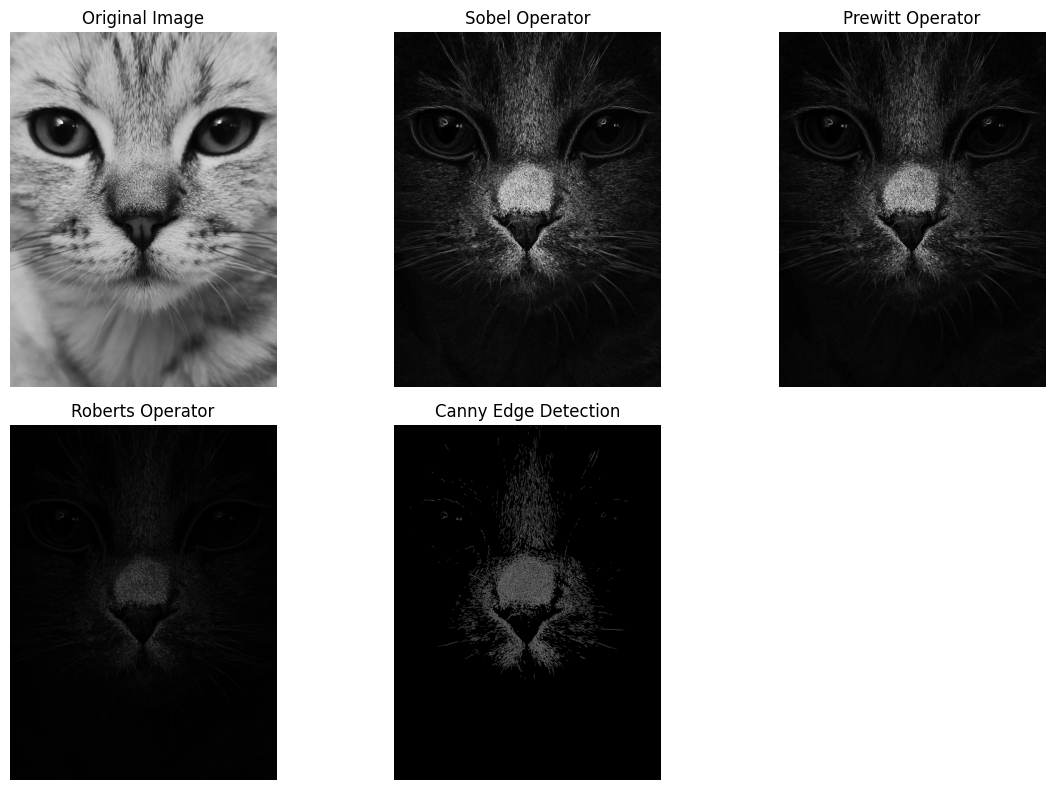

In [12]:
# For the given image perform edge detection using different operators and 
# compare the results.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------
# 1. Read the image
# ---------------------------------------
image = cv2.imread(r"C:\Users\Jayed\OneDrive\Pictures\Desktop\3.2\image and speech\cat.jpg", cv2.IMREAD_GRAYSCALE)

# ---------------------------------------
# 2. Sobel Edge Detection
# ---------------------------------------
sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)

sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel)

# ---------------------------------------
# 3. Prewitt Edge Detection
# ---------------------------------------
prewitt_x = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

prewitt_y = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
])

px = cv2.filter2D(image, cv2.CV_64F, prewitt_x)
py = cv2.filter2D(image, cv2.CV_64F, prewitt_y)

prewitt = cv2.magnitude(px, py)
prewitt = cv2.convertScaleAbs(prewitt)

# ---------------------------------------
# 4. Roberts Edge Detection
# ---------------------------------------
roberts_x = np.array([
    [1, 0],
    [0, -1]
])

roberts_y = np.array([
    [0, 1],
    [-1, 0]
])

rx = cv2.filter2D(image, cv2.CV_64F, roberts_x)
ry = cv2.filter2D(image, cv2.CV_64F, roberts_y)

roberts = cv2.magnitude(rx, ry)
roberts = cv2.convertScaleAbs(roberts)

# ---------------------------------------
# 5. Canny Edge Detection
# ---------------------------------------
canny = cv2.Canny(image, 100, 200)

# ---------------------------------------
# 6. Display and Compare
# ---------------------------------------
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(sobel, cmap="gray")
plt.title("Sobel Operator")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(prewitt, cmap="gray")
plt.title("Prewitt Operator")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(roberts, cmap="gray")
plt.title("Roberts Operator")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(canny, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()


# Lab 8

Area of each coin:
Coin 1: 16741.55 pixels
Coin 2: 13273.23 pixels
Coin 3: 9160.88 pixels
Coin 4: 9160.88 pixels
Coin 5: 15836.77 pixels
Coin 6: 16286.02 pixels
Coin 7: 16286.02 pixels
Coin 8: 8494.87 pixels
Coin 9: 8824.73 pixels


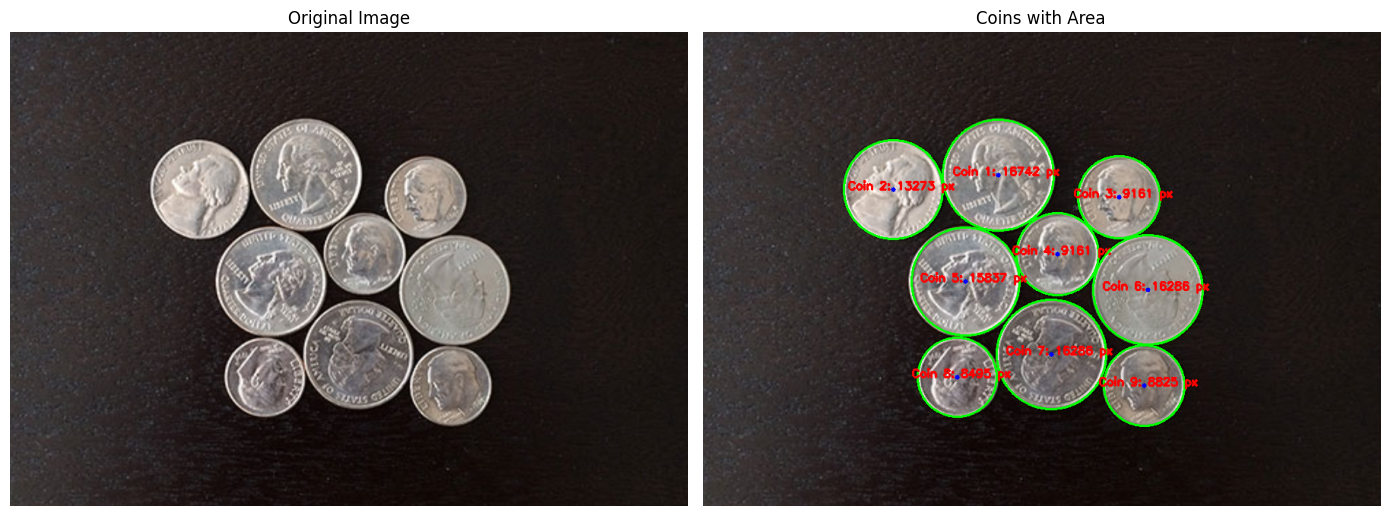

In [ ]:
"""
Yahiya boss
py -m pip install opencv-python numpy matplotlib
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("coins.png")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Reduce noise
gray = cv2.GaussianBlur(gray, (9, 9), 2)

# Detect circles
circles = cv2.HoughCircles(
    gray,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=65,
    param1=100,
    param2=45,
    minRadius=40,
    maxRadius=90
)

result = img.copy()

if circles is not None:

    circles = np.round(circles[0]).astype(int)

    # Sort circles from top to bottom
    circles = sorted(circles, key=lambda c: (c[1], c[0]))

    print("Area of each coin:")

    for i, (x, y, r) in enumerate(circles, 1):

        # Area of circle
        area = np.pi * r * r

        # Draw circle
        cv2.circle(result, (x, y), r, (0, 255, 0), 2)

        # Draw center
        cv2.circle(result, (x, y), 3, (255, 0, 0), -1)

        # Display area
        text = f"Coin {i}: {area:.0f} px"

        cv2.putText(
            result,
            text,
            (x - 60, y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 0, 255),
            2
        )

        print(f"Coin {i}: {area:.2f} pixels")

else:
    print("No coins detected.")

# Convert BGR to RGB for matplotlib
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
result_rgb = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

# Display
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result_rgb)
plt.title("Coins with Area")
plt.axis("off")

plt.tight_layout()
plt.show()

# Lab 9

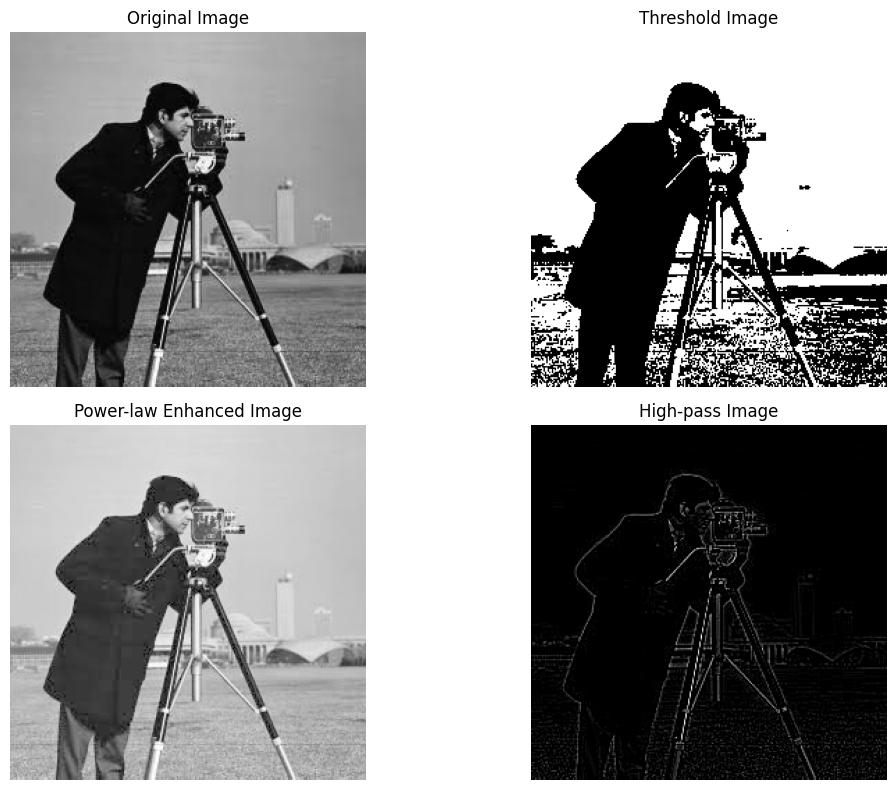

In [16]:
# Display following image operation in MATLAB/Python - i) Threshold 
# image ii) Power enhance contract image iii) High pass image. 

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read original image
img_color = cv2.imread(r"C:\Users\Jayed\OneDrive\Pictures\Desktop\3.2\image and speech\cameraman.jpeg")

# Convert to grayscale
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# i) Threshold Image
_, threshold = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

# ii) Power-law Enhancement
gamma = 0.5

normalized = img_gray / 255.0
power_img = np.power(normalized, gamma)
power_img = np.uint8(power_img * 255)

# iii) High-pass Image
blur = cv2.GaussianBlur(img_gray, (5, 5), 0)
high_pass = cv2.subtract(img_gray, blur)

# Display
plt.figure(figsize=(12, 8))

# Original
plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Threshold
plt.subplot(2, 2, 2)
plt.imshow(threshold, cmap="gray")
plt.title("Threshold Image")
plt.axis("off")

# Power-law
plt.subplot(2, 2, 3)
plt.imshow(power_img, cmap="gray")
plt.title("Power-law Enhanced Image")
plt.axis("off")

# High-pass
plt.subplot(2, 2, 4)
plt.imshow(high_pass, cmap="gray")
plt.title("High-pass Image")
plt.axis("off")

plt.tight_layout()
plt.show()

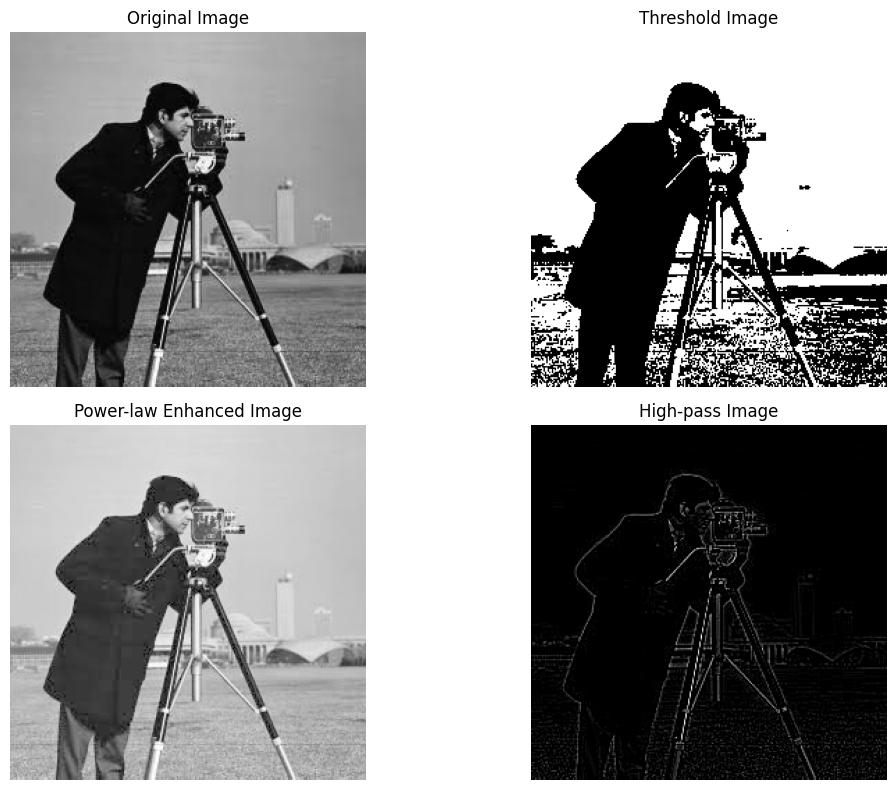

In [21]:
"""
Yahiya boss
py -m pip install opencv-python numpy matplotlib
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read original image in color
img_color = cv2.imread("cameraman.jpeg")

# Convert a copy to grayscale for image processing
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# i) Threshold Image
_, threshold = cv2.threshold(
    img_gray, 127, 255, cv2.THRESH_BINARY
)

# ii) Power-law Enhancement
gamma = 0.5

normalized = img_gray / 255.0
power_img = np.power(normalized, gamma)
power_img = np.uint8(power_img * 255)

# iii) High-pass Image
blur = cv2.GaussianBlur(img_gray, (5, 5), 0)
high_pass = cv2.subtract(img_gray, blur)

# Display Results
plt.figure(figsize=(12, 8))

# Original image
plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

# Threshold
plt.subplot(2, 2, 2)
plt.imshow(threshold, cmap="gray")
plt.title("Threshold Image")
plt.axis("off")

# Power-law
plt.subplot(2, 2, 3)
plt.imshow(power_img, cmap="gray")
plt.title("Power-law Enhanced Image")
plt.axis("off")

# High-pass
plt.subplot(2, 2, 4)
plt.imshow(high_pass, cmap="gray")
plt.title("High-pass Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# Lab 10

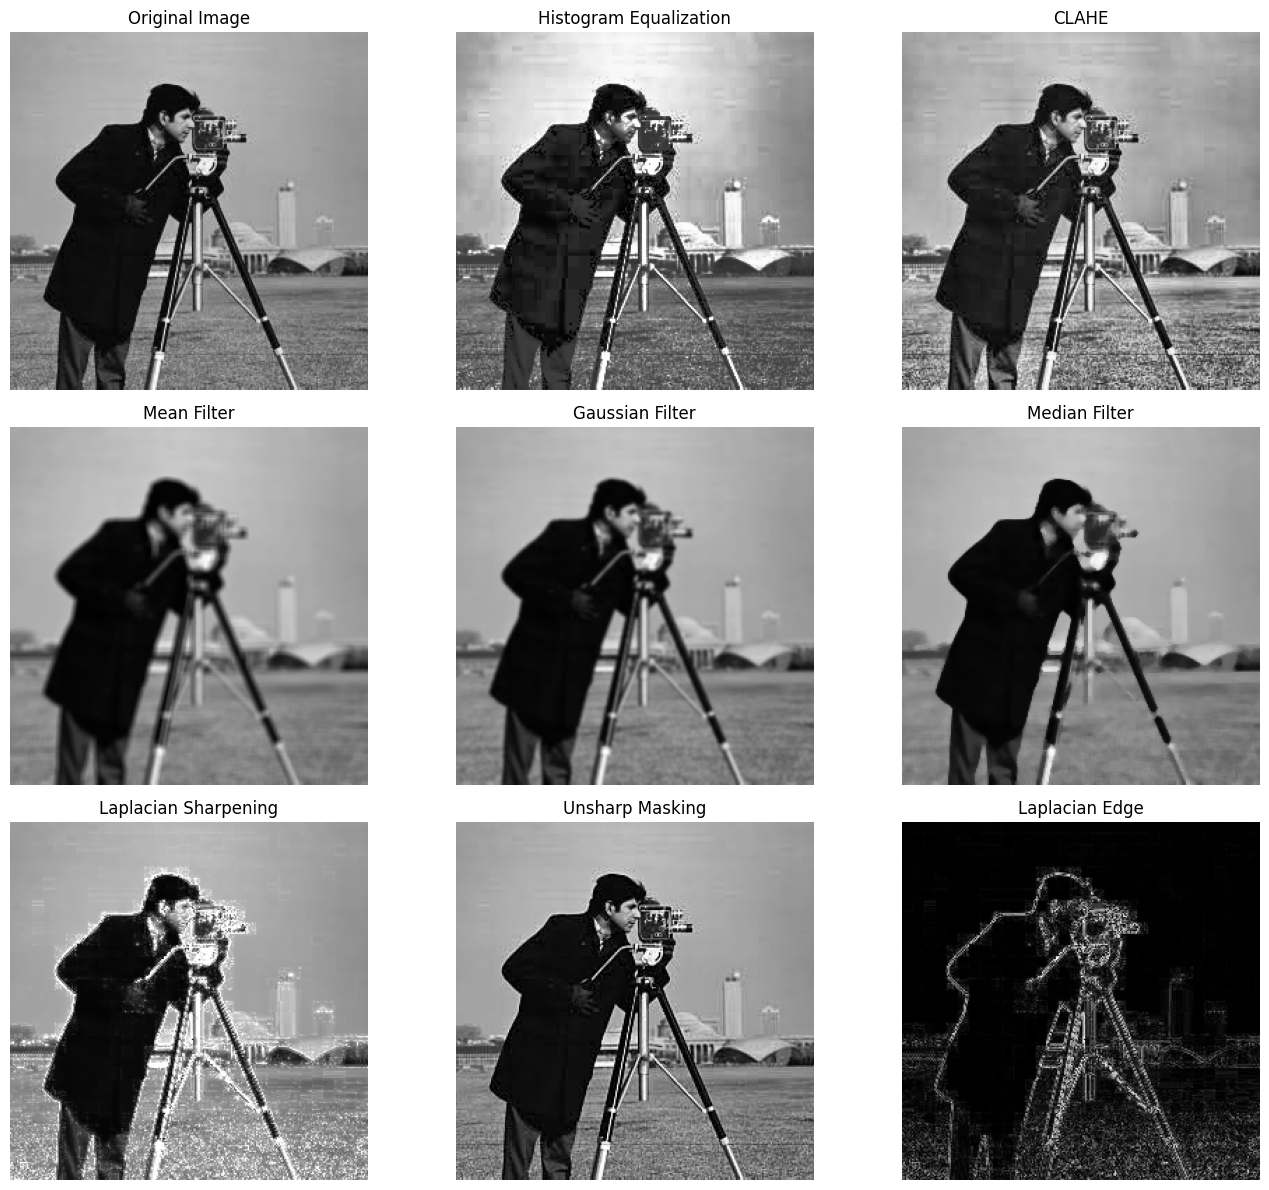

In [19]:
# Perform image enhancement, smoothing and sharpening, in spatial domain 
# using different spatial filters and compare the performances  

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read Image

img = cv2.imread(r"C:\Users\Jayed\OneDrive\Pictures\Desktop\3.2\image and speech\cameraman.jpeg")

if img is None:
    print("Error: Image not found. Check the file path.")
    exit()

# Convert BGR to RGB for display
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 1. IMAGE ENHANCEMENT

# Histogram Equalization
hist_eq = cv2.equalizeHist(gray)

# CLAHE (Contrast Limited Adaptive Histogram Equalization)
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

clahe_img = clahe.apply(gray)

# 2. IMAGE SMOOTHING

# Mean / Average Filter
mean_filter = cv2.blur(gray, (5, 5))

# Gaussian Filter
gaussian_filter = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

# Median Filter
median_filter = cv2.medianBlur(
    gray,
    5
)

# 3. IMAGE SHARPENING

# ---------- Laplacian Sharpening ----------

laplacian = cv2.Laplacian(
    gray,
    cv2.CV_64F
)

laplacian = np.uint8(
    np.absolute(laplacian)
)

laplacian_sharp = cv2.add(
    gray,
    laplacian
)

# ---------- Unsharp Masking ----------

blurred = cv2.GaussianBlur(
    gray,
    (5, 5),
    0
)

# Unsharp masking
unsharp = cv2.addWeighted(
    gray,
    1.5,
    blurred,
    -0.5,
    0
)

# DISPLAY RESULTS

plt.figure(figsize=(14, 12))

# Original
plt.subplot(3, 3, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

# Histogram Equalization
plt.subplot(3, 3, 2)
plt.imshow(hist_eq, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

# CLAHE
plt.subplot(3, 3, 3)
plt.imshow(clahe_img, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

# Mean Filter
plt.subplot(3, 3, 4)
plt.imshow(mean_filter, cmap="gray")
plt.title("Mean Filter")
plt.axis("off")

# Gaussian Filter
plt.subplot(3, 3, 5)
plt.imshow(gaussian_filter, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")

# Median Filter
plt.subplot(3, 3, 6)
plt.imshow(median_filter, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

# Laplacian Sharpening
plt.subplot(3, 3, 7)
plt.imshow(laplacian_sharp, cmap="gray")
plt.title("Laplacian Sharpening")
plt.axis("off")

# Unsharp Masking
plt.subplot(3, 3, 8)
plt.imshow(unsharp, cmap="gray")
plt.title("Unsharp Masking")
plt.axis("off")

# Edge Image
plt.subplot(3, 3, 9)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian Edge")
plt.axis("off")

plt.tight_layout()
plt.show()

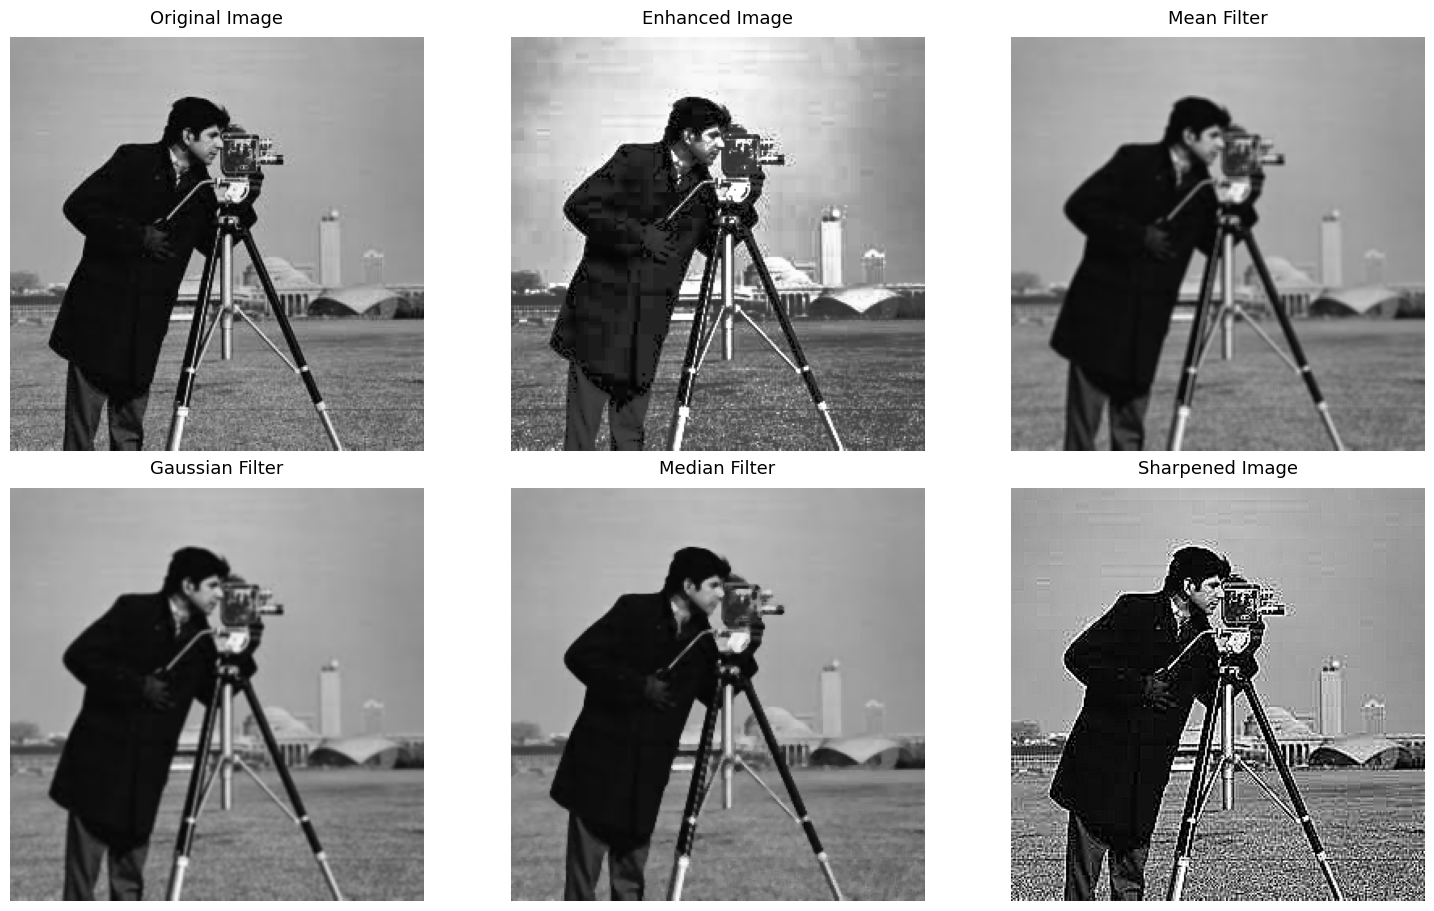

In [20]:
"""
yahiya boss
py -m pip install opencv-python numpy matplotlib
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the original image in COLOR
img = cv2.imread("cameraman.jpeg", cv2.IMREAD_COLOR)

if img is None:
    raise FileNotFoundError("Could not load cat.png. Check the file path.")

# OpenCV uses BGR; convert to RGB for Matplotlib display
original = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Image enhancement using histogram equalization
# Apply equalization to brightness, not each color channel separately
ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)
ycrcb[:, :, 0] = cv2.equalizeHist(ycrcb[:, :, 0])
enhanced_bgr = cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)
enhanced = cv2.cvtColor(enhanced_bgr, cv2.COLOR_BGR2RGB)

# 3. Smoothing filters
mean_bgr = cv2.blur(img, (3, 3))
gaussian_bgr = cv2.GaussianBlur(img, (3, 3), 0)
median_bgr = cv2.medianBlur(img, 3)

mean = cv2.cvtColor(mean_bgr, cv2.COLOR_BGR2RGB)
gaussian = cv2.cvtColor(gaussian_bgr, cv2.COLOR_BGR2RGB)
median = cv2.cvtColor(median_bgr, cv2.COLOR_BGR2RGB)

# 4. Sharpening filter
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharp_bgr = cv2.filter2D(img, -1, kernel)
sharp = cv2.cvtColor(sharp_bgr, cv2.COLOR_BGR2RGB)

# 5. Compare all results
titles = [
    "Original Image",
    "Enhanced Image",
    "Mean Filter",
    "Gaussian Filter",
    "Median Filter",
    "Sharpened Image"
]

images = [original, enhanced, mean, gaussian, median, sharp]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9),
    constrained_layout=True
)

for ax, title, image in zip(axes.flat, titles, images):
    ax.imshow(image)
    ax.set_title(title, fontsize=13, pad=10)
    ax.axis("off")

plt.show()

# Lab 12

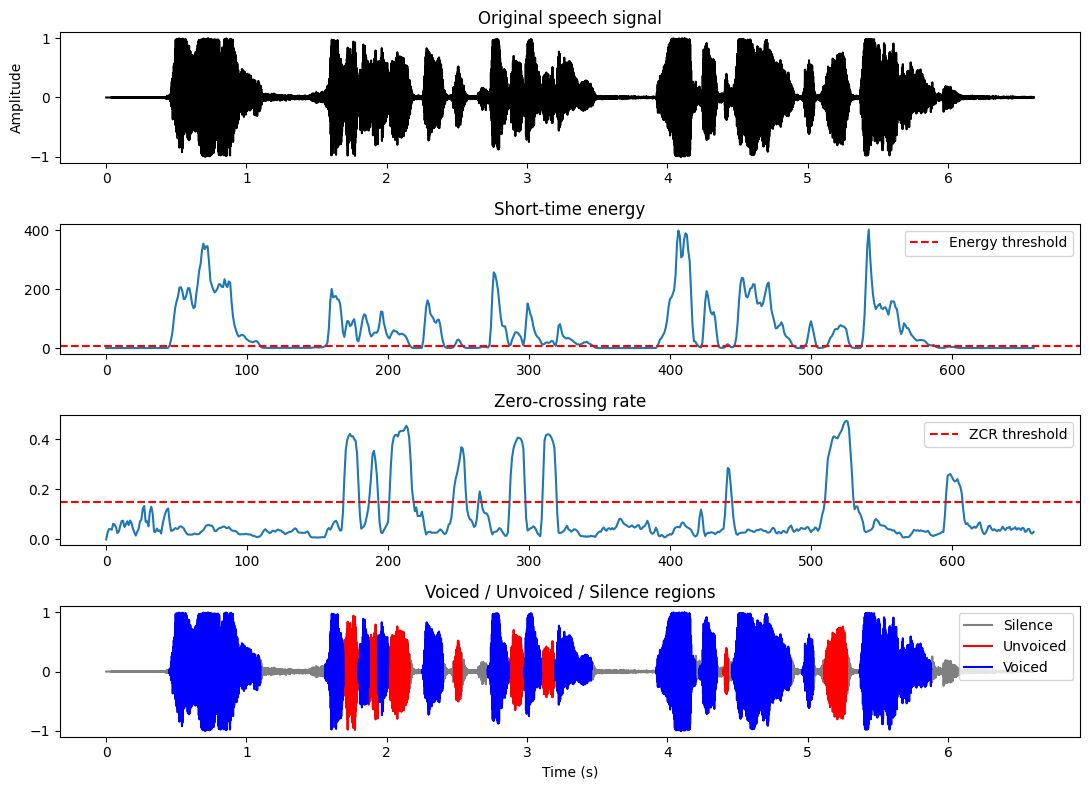

In [22]:
"""
Q12: Separation of voiced / unvoiced / silence regions of a speech signal
Method: Short-Time Energy (STE) + Zero Crossing Rate (ZCR)

    Silence  -> very low energy
    Voiced   -> high energy, LOW  zero-crossing rate
    Unvoiced -> lower energy, HIGH zero-crossing rate (noise-like)

Requires: numpy, scipy, matplotlib   (pip install numpy scipy matplotlib)
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

# ---------- 1. Read the signal ----------
fs, x = wavfile.read('audio.wav')
if x.ndim > 1:                      # stereo -> mono
    x = x.mean(axis=1)
x = x.astype(float)
x = x / np.max(np.abs(x))           # normalise to [-1, 1]
t = np.arange(len(x)) / fs

# ---------- 2. Framing (25 ms frame, 10 ms hop) ----------
frame_len = int(0.025 * fs)
hop = int(0.010 * fs)
n_frames = 1 + (len(x) - frame_len) // hop

energy = np.zeros(n_frames)
zcr = np.zeros(n_frames)
for i in range(n_frames):
    seg = x[i * hop: i * hop + frame_len]
    energy[i] = np.sum(seg ** 2)                          # short-time energy
    zcr[i] = 0.5 * np.mean(np.abs(np.diff(np.sign(seg))))  # zero-crossing rate

# ---------- 3. Thresholds (tune these for your recording) ----------
E_thr = 0.02 * np.max(energy)       # below this  -> silence
Z_thr = 0.15                        # above this  -> unvoiced, else voiced

# ---------- 4. Classify each frame: 0 = silence, 1 = unvoiced, 2 = voiced ----------
label = np.zeros(n_frames, dtype=int)
for i in range(n_frames):
    if energy[i] < E_thr:
        label[i] = 0
    elif zcr[i] > Z_thr:
        label[i] = 1
    else:
        label[i] = 2

# ---------- 5. Expand frame labels to sample level ----------
sample_label = np.zeros(len(x), dtype=int)
for i in range(n_frames):
    sample_label[i * hop: i * hop + hop] = label[i]
sample_label[n_frames * hop:] = label[-1]

# ---------- 6. Plots ----------
names = ['Silence', 'Unvoiced', 'Voiced']
colors = ['gray', 'red', 'blue']

plt.figure(figsize=(11, 8))

plt.subplot(4, 1, 1)
plt.plot(t, x, 'k')
plt.title('Original speech signal'); plt.ylabel('Amplitude')

plt.subplot(4, 1, 2)
plt.plot(energy); plt.axhline(E_thr, color='r', ls='--', label='Energy threshold')
plt.title('Short-time energy'); plt.legend()

plt.subplot(4, 1, 3)
plt.plot(zcr); plt.axhline(Z_thr, color='r', ls='--', label='ZCR threshold')
plt.title('Zero-crossing rate'); plt.legend()

plt.subplot(4, 1, 4)
for c in range(3):
    y = np.where(sample_label == c, x, np.nan)
    plt.plot(t, y, color=colors[c], label=names[c])
plt.title('Voiced / Unvoiced / Silence regions')
plt.xlabel('Time (s)'); plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

# Lab 13

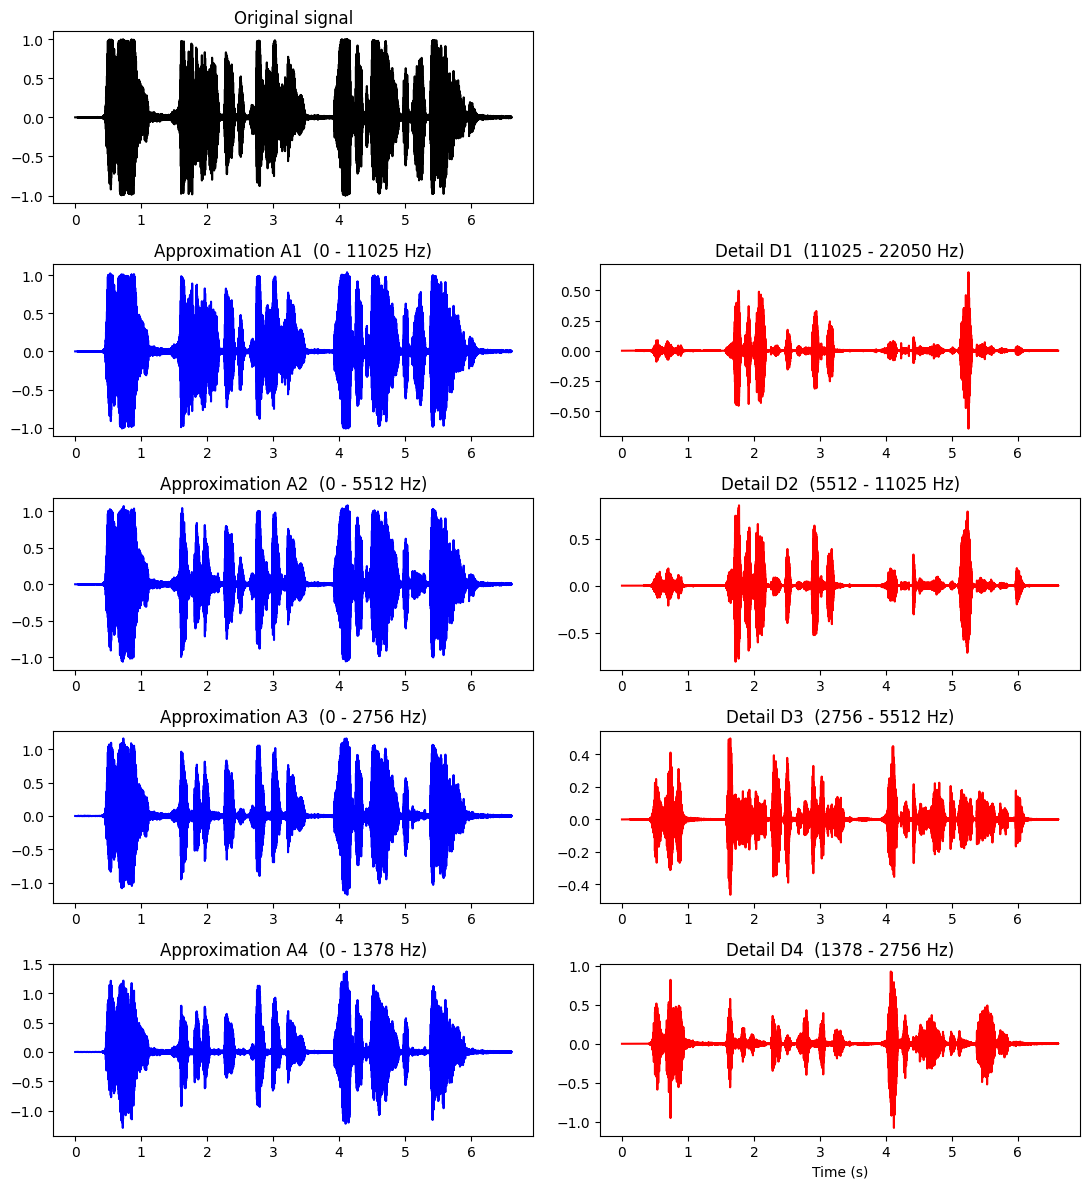

Max reconstruction error: 9.992007221626409e-16


In [1]:
# Write a MATLAB/Python program and plot multilevel speech resolution.

# python -m pip install numpy matplotlib PyWavelets scipy

import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy.io import wavfile

# ---------- 1. Read the signal ----------
fs, x = wavfile.read('audio.wav')
if x.ndim > 1:
    x = x.mean(axis=1)
x = x.astype(float)
x = x / np.max(np.abs(x))
t = np.arange(len(x)) / fs

wavelet = 'db4'
levels = 4

# ---------- 2. Multilevel decomposition ----------
# coeffs = [cA4, cD4, cD3, cD2, cD1]
coeffs = pywt.wavedec(x, wavelet, level=levels)


def reconstruct(keep_index):
    """Rebuild a full-length signal using only ONE coefficient set."""
    c = [np.zeros_like(a) for a in coeffs]
    c[keep_index] = coeffs[keep_index]
    return pywt.waverec(c, wavelet)[:len(x)]


# Approximation at the deepest level and details at every level
approx = reconstruct(0)                                   # A4
details = {k: reconstruct(levels - k + 1) for k in range(1, levels + 1)}  # D1..D4

# Approximations at intermediate levels A1..A3 (decompose to that level, keep cA)
approximations = {}
for k in range(1, levels + 1):
    ck = pywt.wavedec(x, wavelet, level=k)
    ck = [ck[0]] + [np.zeros_like(a) for a in ck[1:]]
    approximations[k] = pywt.waverec(ck, wavelet)[:len(x)]

# ---------- 3. Plot ----------
plt.figure(figsize=(11, 12))

plt.subplot(levels + 1, 2, 1)
plt.plot(t, x, 'k'); plt.title('Original signal')

for k in range(1, levels + 1):
    plt.subplot(levels + 1, 2, 2 * k + 1)
    plt.plot(t, approximations[k], 'b')
    plt.title(f'Approximation A{k}  (0 - {fs / 2 ** (k + 1):.0f} Hz)')

    plt.subplot(levels + 1, 2, 2 * k + 2)
    plt.plot(t, details[k], 'r')
    plt.title(f'Detail D{k}  ({fs / 2 ** (k + 1):.0f} - {fs / 2 ** k:.0f} Hz)')

plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()

# ---------- 4. Check: A4 + D4 + D3 + D2 + D1 gives back the original ----------
recon = approx + sum(details.values())
print('Max reconstruction error:', np.max(np.abs(x - recon)))

# Lab 14

In [2]:
# Write a MATLAB/Python program to recognize speech signal

# Install required packages:
# pip install SpeechRecognition
# pip install pydub  # Optional, for some audio formats

# python -m pip install SpeechRecognition


import speech_recognition as sr

# Create recognizer object
recognizer = sr.Recognizer()

# Load speech file
with sr.AudioFile("audio.wav") as source:
    audio = recognizer.record(source)

# Recognize speech
try:
    result = recognizer.recognize_google(audio)

    print("Recognized Speech:")
    print(result)

except sr.UnknownValueError:
    print("Sorry, speech could not be understood.")

except sr.RequestError:
    print("Could not connect to the recognition service.")

Recognized Speech:
hello this is a speech processing laboratory experiment


# Lab 15


Recording will start now...
Speak clearly for 5 seconds.
Recording finished.
Speech saved as: recorded_speech.wav
Playing recorded speech...


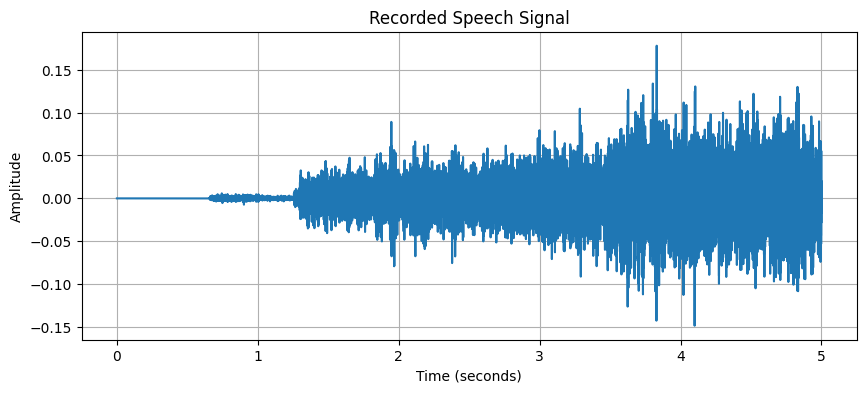

In [2]:
# Write a MATLAB/Python program for text-to-speech conversion and record 
# speech signal.

# """
# Required packages, command: pip install pyttsx3 sounddevice soundfile numpy matplotlib
# """

import pyttsx3
import sounddevice as sd
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

# ---------------- TEXT TO SPEECH ----------------
text = "Welcome to Speech Processing Lab."

engine = pyttsx3.init()
engine.say(text)
engine.runAndWait()

# ---------------- SPEECH RECORDING ----------------
fs = 44100          # Sampling frequency
duration = 5        # Recording time in seconds

print("\nRecording will start now...")
print("Speak clearly for 5 seconds.")

recording = sd.rec(
    int(duration * fs),
    samplerate=fs,
    channels=1,
    dtype='float32'
)

sd.wait()   # Wait until recording is finished

print("Recording finished.")

# Save the recorded speech
filename = "recorded_speech.wav"
sf.write(filename, recording, fs)

print("Speech saved as:", filename)

# ---------------- PLAY RECORDED SPEECH ----------------
print("Playing recorded speech...")
sd.play(recording, fs)
sd.wait()

# ---------------- PLOT SPEECH SIGNAL ----------------
time = np.arange(len(recording)) / fs

plt.figure(figsize=(10, 4))
plt.plot(time, recording)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Recorded Speech Signal")
plt.grid()
plt.show()